# 09. Integrated Environment and Baseline Audit

This notebook combines the pollutant equations, regional economic assumptions, synthetic pollution-damage feedback, and mitigation projects in one annual environment. It compares fixed policies only. The project and damage values remain assumptions, and no reward function or trained agent is used.

The pollutant-only environment remains available for the earlier audits. This notebook uses the new integrated environment and checks its state, resource, and mass-balance behavior before any RL work.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from study_3_pollutant_dynamics.config import EnvironmentConfig
from study_3_pollutant_dynamics.baseline_regression import (REFERENCE_BASELINE_SETTINGS, REFERENCE_BASELINE_POLICIES,
                                                            compare_reference_baseline)

from study_3_pollutant_dynamics.integrated_environment import (INTEGRATED_ACTIONS, Study3IntegratedEnvironment)
from study_3_pollutant_dynamics.policy_evaluation import (FIXED_POLICY_NAMES, evaluate_fixed_policies, run_fixed_policy_episode,
                                                          summarize_integrated_episode)

from study_3_pollutant_dynamics.scenario_parameters import get_parameters
from study_3_pollutant_dynamics.economic_parameters import (REGIONAL_ECONOMIC_PARAMETERS, STAGE_2_SCENARIOS)
from study_3_pollutant_dynamics.mitigation_parameters import (DEVELOPMENT_COST_PER_EDI_POINT, MITIGATION_POLICIES,
                                                              PROJECT_PURCHASE_FREQUENCY_YEARS)
from study_3_pollutant_dynamics.regional_economics import calculate_annual_income
from study_3_pollutant_dynamics.mitigation import purchase_costs

## Observation and action interface

The environment returns one observation dictionary per region. CO2 concentration is shared and appears in each regional observation. Pollutant values retain their physical units. EDI, currency, and the region index are additional state variables. Each region selects one of eight named actions per year.

In [2]:
action_rows = []
for action_name, action_settings in INTEGRATED_ACTIONS.items():
    action_rows.append({"action": action_name, "development_points": action_settings["development_points"],
                        "investment_package": action_settings["investment"]})
display(pd.DataFrame(action_rows))

,action,development_points,investment_package
0,maintain,0.0,NaN
1,develop,1.0,NaN
2,prevention,0.0,prevention_focused
3,develop_prevention,1.0,prevention_focused
4,cleanup,0.0,cleanup_focused
5,develop_cleanup,1.0,cleanup_focused
6,balanced,0.0,balanced
7,develop_balanced,1.0,balanced


In [3]:
observation_rows = [
    {"observation": "PM2.5_ug_m3", "units": "ug/m^3", "scope": "regional"},
    {"observation": "CO2_ppm", "units": "ppm", "scope": "shared; repeated per region"},
    {"observation": "Nitrate-N_mg_L", "units": "mg N/L", "scope": "regional"},
    {"observation": "Nitrate-N_stock_kg", "units": "kg N", "scope": "regional"},
    {"observation": "Lead_total_kg", "units": "kg Pb", "scope": "regional"},
    {"observation": "Lead_mobile_kg", "units": "kg Pb", "scope": "regional"},
    {"observation": "EDI", "units": "index points (0-100)", "scope": "regional"},
    {"observation": "currency", "units": "abstract model units", "scope": "regional"},
    {"observation": "region_index", "units": "integer code (0-3)", "scope": "regional"},
]
display(pd.DataFrame(observation_rows))

,observation,units,scope
0,PM2.5_ug_m3,ug/m^3,regional
1,CO2_ppm,ppm,shared; repeated per region
2,Nitrate-N_mg_L,mg N/L,regional
3,Nitrate-N_stock_kg,kg N,regional
4,Lead_total_kg,kg Pb,regional
5,Lead_mobile_kg,kg Pb,regional
6,EDI,index points (0-100),regional
7,currency,abstract model units,regional
8,region_index,integer code (0-3),regional


## Fixed-policy comparison

Each policy starts from the same four regional economic and pollutant conditions. The starting-currency multiplier changes only the initial balances. Note that the dynamics in here are deterministic.

A development action adds one EDI point if it is affordable. Investment actions buy the corresponding project package when the five-year purchase schedule allows it. Development is charged before investment, and annual net income is added after pollution damage is calculated.

In [4]:
POLICIES = list(FIXED_POLICY_NAMES)
CURRENCY_MULTIPLIERS = [0.5, REFERENCE_BASELINE_SETTINGS["starting_currency_multiplier"], 1.5]
EPISODE_YEARS = REFERENCE_BASELINE_SETTINGS["episode_steps"]

reference_config = EnvironmentConfig(get_parameters(episode_steps=EPISODE_YEARS))
summary_rows = evaluate_fixed_policies(
    reference_config,
    policy_names=POLICIES,
    currency_multipliers=CURRENCY_MULTIPLIERS,
    seeds=(REFERENCE_BASELINE_SETTINGS["seed"],),
    development_cost_multiplier=REFERENCE_BASELINE_SETTINGS["development_cost_multiplier"],
    investment_cost_multiplier=REFERENCE_BASELINE_SETTINGS["investment_cost_multiplier"],
    development_cost_shape=REFERENCE_BASELINE_SETTINGS["development_cost_shape"],
    income_damage_multiplier=REFERENCE_BASELINE_SETTINGS["income_damage_multiplier"],
    income_damage_persistence=REFERENCE_BASELINE_SETTINGS["income_damage_persistence"],
)
policy_results = pd.DataFrame(summary_rows)

In [5]:
policy_economics = policy_results[["policy", "starting_currency_multiplier", "final_mean_EDI", "final_min_EDI",
                                   "final_mean_currency", "minimum_currency", "development_spending", "mitigation_spending",
                                    "investment_package_purchases", "unaffordable_development_attempts", "unaffordable_investment_attempts"]]
display(policy_economics.round(3))

,policy,starting_currency_multiplier,final_mean_EDI,final_min_EDI,final_mean_currency,minimum_currency,development_spending,mitigation_spending,investment_package_purchases,unaffordable_development_attempts,unaffordable_investment_attempts
0,no_development_no_investment,0.5,65.00,55.0,4208.091,275.605,0.0,0.0,0,0,0
1,no_development_no_investment,1.0,65.00,55.0,4520.591,500.605,0.0,0.0,0,0,0
2,no_development_no_investment,1.5,65.00,55.0,4833.091,725.605,0.0,0.0,0,0,0
3,development_only,0.5,98.75,95.0,3432.007,250.605,3375.0,0.0,0,0,0
4,development_only,1.0,98.75,95.0,3744.507,475.605,3375.0,0.0,0,0,0
5,development_only,1.5,98.75,95.0,4057.007,700.605,3375.0,0.0,0,0,0
6,prevention_focused,0.5,98.75,95.0,3161.222,170.605,3375.0,2560.0,32,0,0
7,prevention_focused,1.0,98.75,95.0,3473.722,395.605,3375.0,2560.0,32,0,0
8,prevention_focused,1.5,98.75,95.0,3786.222,620.605,3375.0,2560.0,32,0,0
9,cleanup_focused,0.5,98.75,95.0,2875.563,150.605,3375.0,3200.0,32,0,0


The economic table separates growth from spending. A low final balance can reflect successful investment as well as weak income. The affordability columns show when an intended development or project purchase could not be paid for. There is no environmental failure threshold in this prototype, so an episode is not labeled a failure solely because a concentration is high.

After rerunning with the current integrated code, all regions complete every requested development action and purchase all 32 scheduled packages under the reference setting, including at 0.5x starting currency. At 1.0x starting currency, development-only and balanced both finish at mean EDI 98.75. Balanced spends 6,400 currency units and ends with mean currency 2,735.40, compared with 3,744.51 for development-only.

## Shared baseline regression check

In [6]:
shared_baseline_rows = []
for result_row in policy_results.to_dict("records"):
    matching_currency = result_row["starting_currency_multiplier"] == REFERENCE_BASELINE_SETTINGS["starting_currency_multiplier"]
    matching_policy = result_row["policy"] in REFERENCE_BASELINE_POLICIES
    if matching_currency and matching_policy:
        shared_baseline_rows.append(result_row)

baseline_check_rows = compare_reference_baseline(shared_baseline_rows)
baseline_checks = pd.DataFrame(baseline_check_rows)
display(baseline_checks)

,policy,metric,expected,actual,passed
0,development_only,final_mean_EDI,98.750000,98.750000,True
1,development_only,final_min_EDI,95.000000,95.000000,True
2,development_only,final_mean_currency,3744.507401,3744.507401,True
3,development_only,minimum_currency,475.605311,475.605311,True
4,development_only,development_spending,3375.000000,3375.000000,True
5,development_only,mitigation_spending,0.000000,0.000000,True
6,development_only,investment_package_purchases,0.000000,0.000000,True
7,development_only,unaffordable_development_attempts,0.000000,0.000000,True
8,development_only,final_CO2_ppm,529.662055,529.662055,True
9,development_only,final_mean_PM2.5_ug_m3,8.613520,8.613520,True


In [7]:
passed_checks = int(baseline_checks["passed"].sum())
total_checks = len(baseline_checks)
print(f"Passed {passed_checks} of {total_checks} shared baseline checks.")
if passed_checks != total_checks:
    raise ValueError("Notebook 09 baseline changed; review the current model and update the regression fixture only if intended.")

Passed 36 of 36 shared baseline checks.


In [8]:
policy_environment = policy_results[["policy", "starting_currency_multiplier", "final_CO2_ppm", "peak_CO2_ppm",
                                     "final_mean_PM2.5_ug_m3", "final_mean_nitrate_mg_N_L",
                                     "final_mean_lead_total_kg", "final_mean_lead_mobile_kg"]]
display(policy_environment.round(4))

,policy,starting_currency_multiplier,final_CO2_ppm,peak_CO2_ppm,final_mean_PM2.5_ug_m3,final_mean_nitrate_mg_N_L,final_mean_lead_total_kg,final_mean_lead_mobile_kg
0,no_development_no_investment,0.5,525.6200,525.6200,8.5630,2.2575,16.2153,0.0063
1,no_development_no_investment,1.0,525.6200,525.6200,8.5630,2.2575,16.2153,0.0063
2,no_development_no_investment,1.5,525.6200,525.6200,8.5630,2.2575,16.2153,0.0063
3,development_only,0.5,529.6621,529.6621,8.6135,3.2094,17.1226,0.0066
4,development_only,1.0,529.6621,529.6621,8.6135,3.2094,17.1226,0.0066
5,development_only,1.5,529.6621,529.6621,8.6135,3.2094,17.1226,0.0066
6,prevention_focused,0.5,526.7494,526.7494,8.5701,2.5675,15.9208,0.0062
7,prevention_focused,1.0,526.7494,526.7494,8.5701,2.5675,15.9208,0.0062
8,prevention_focused,1.5,526.7494,526.7494,8.5701,2.5675,15.9208,0.0062
9,cleanup_focused,0.5,529.5229,529.5229,8.6135,3.0869,12.9078,0.0050


CO2 is shared across all regions. PM2.5 is reported as mean annual exposure, nitrate as mean receiving-water concentration, and lead as total and mobile soil mass. Compare each pollutant column with its own units in mind. In the integrated model, the PM2.5 source term is the emissions change from the initial activity baseline; a region at its initial EDI with no prevention therefore stays at its baseline exposure. The assumed 5,000-ton reference source mass and the regional profile multipliers are synthetic. Lower endpoints indicate only that a policy performed better under these chosen equations and parameters.

In [9]:
trajectory_results = {}
for policy_name in POLICIES:
    environment = Study3IntegratedEnvironment(EnvironmentConfig(get_parameters(episode_steps=EPISODE_YEARS)), starting_currency_multiplier=1.0)
    trajectory, terminated, truncated = run_fixed_policy_episode(policy_name, environment, seed=0)
    trajectory_results[policy_name] = trajectory

In [10]:
plot_specs = [("Mean EDI", "EDI"), ("CO2 (ppm)", "CO2"), ("PM2.5 (ug/m^3)", "PM2.5"), ("Nitrate-N (mg N/L)", "Nitrate-N"), ("Total soil lead (kg)", "Lead"), ("Mobile soil lead (kg)", "Mobile Lead")]
plot_data = {}

for policy_name in POLICIES:
    policy_data = {
        "year": [],
        "EDI": [],
        "CO2": [],
        "PM2.5": [],
        "Nitrate-N": [],
        "Lead": [],
        "Mobile Lead": [],
    }

    for info in trajectory_results[policy_name]:
        policy_data["year"].append(info["step"])

        regional_edi = []

        for result in info["regional_economy"]:
            regional_edi.append(result["EDI"])

        mean_edi = sum(regional_edi) / len(regional_edi)
        mean_pm25 = sum(info["stocks"]["PM2.5"]) / len(reference_config.regions)
        mean_lead = sum(info["stocks"]["Lead"]) / len(reference_config.regions)
        mean_mobile_lead = sum(info["mobile_stocks"]["Lead"]) / len(reference_config.regions)

        nitrate_concentrations = []

        for stock in info["stocks"]["Nitrate-N"]:
            concentration = 1000 * stock / reference_config.nitrate["water_volume_m3"]
            nitrate_concentrations.append(concentration)

        mean_nitrate = sum(nitrate_concentrations) / len(nitrate_concentrations)

        policy_data["EDI"].append(mean_edi)
        policy_data["CO2"].append(info["stocks"]["CO2"])
        policy_data["PM2.5"].append(mean_pm25)
        policy_data["Nitrate-N"].append(mean_nitrate)
        policy_data["Lead"].append(mean_lead)
        policy_data["Mobile Lead"].append(mean_mobile_lead)

    plot_data[policy_name] = policy_data

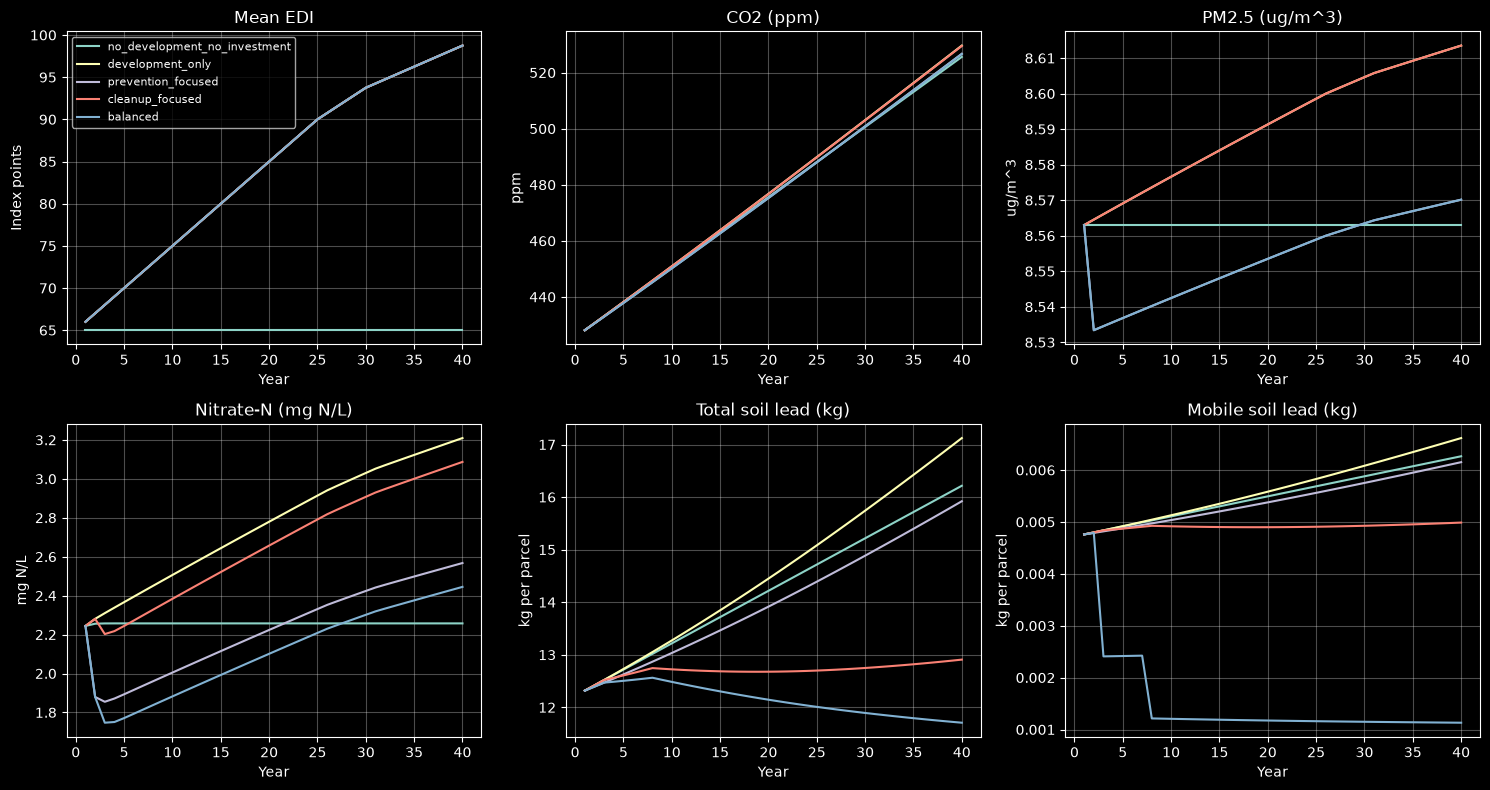

In [11]:
figure, axes = plt.subplots(2, 3, figsize=(15, 8))

for plot_index, (plot_title, measure) in enumerate(plot_specs):
    axis = axes.flat[plot_index]

    for policy_name in POLICIES:
        years = plot_data[policy_name]["year"]
        values = plot_data[policy_name][measure]

        axis.plot(years, values, label=policy_name)

    axis.set_title(plot_title)
    axis.set_xlabel("Year")
    axis.grid(True, alpha=0.3)

axes.flat[0].set_ylabel("Index points")
axes.flat[1].set_ylabel("ppm")
axes.flat[2].set_ylabel("ug/m^3")
axes.flat[3].set_ylabel("mg N/L")
axes.flat[4].set_ylabel("kg per parcel")
axes.flat[5].set_ylabel("kg per parcel")

axes.flat[0].legend(fontsize=8)

figure.tight_layout()
plt.show()

The trajectories show when strategy differences emerge. Prevention affects new inputs after its delay, cleanup acts on pollutant stocks after its delay, and lead containment changes the mobile fraction without removing total soil lead.

In [12]:
audit_rows = []
for row in summary_rows:
    audit_rows.append({
        "policy": row["policy"],
        "currency_multiplier": row["starting_currency_multiplier"],
        "completed_40_years": row["completed_horizon"],
        "currency_nonnegative": row["minimum_currency"] >= -1e-9,
        "EDI_within_0_100": row["maximum_EDI"] <= 100.0 and row["final_min_EDI"] >= 0.0,
        "pollutant_stocks_nonnegative": row["pollutant_stocks_nonnegative"],
        "state_values_finite": row["state_values_finite"],
        "nitrate_mass_balance_ok": row["maximum_nitrate_mass_balance_residual_kg"] < 1e-5,
        "lead_mass_balance_ok": row["maximum_lead_mass_balance_residual_kg"] < 1e-9,
        "max_nitrate_residual_kg": row["maximum_nitrate_mass_balance_residual_kg"],
        "max_lead_residual_kg": row["maximum_lead_mass_balance_residual_kg"],
    })

In [13]:
audit_table = pd.DataFrame(audit_rows)
check_columns = [
    "completed_40_years",
    "currency_nonnegative",
    "EDI_within_0_100",
    "pollutant_stocks_nonnegative",
    "state_values_finite",
    "nitrate_mass_balance_ok",
    "lead_mass_balance_ok",
]
display(audit_table.round(10))
passed_checks = int(audit_table[check_columns].sum().sum())
total_checks = len(audit_table) * len(check_columns)
print(f"Passed {passed_checks} of {total_checks} checks.")

,policy,currency_multiplier,completed_40_years,currency_nonnegative,EDI_within_0_100,pollutant_stocks_nonnegative,state_values_finite,nitrate_mass_balance_ok,lead_mass_balance_ok,max_nitrate_residual_kg,max_lead_residual_kg
0,no_development_no_investment,0.5,True,True,True,True,True,True,True,4.470000e-08,0.0
1,no_development_no_investment,1.0,True,True,True,True,True,True,True,4.470000e-08,0.0
2,no_development_no_investment,1.5,True,True,True,True,True,True,True,4.470000e-08,0.0
3,development_only,0.5,True,True,True,True,True,True,True,5.960000e-08,0.0
4,development_only,1.0,True,True,True,True,True,True,True,5.960000e-08,0.0
5,development_only,1.5,True,True,True,True,True,True,True,5.960000e-08,0.0
6,prevention_focused,0.5,True,True,True,True,True,True,True,4.470000e-08,0.0
7,prevention_focused,1.0,True,True,True,True,True,True,True,4.470000e-08,0.0
8,prevention_focused,1.5,True,True,True,True,True,True,True,4.470000e-08,0.0
9,cleanup_focused,0.5,True,True,True,True,True,True,True,5.960000e-08,0.0


Passed 105 of 105 checks.


These checks cover episode completion, resource constraints, EDI bounds, and nitrate/lead mass accounting including cleanup.

### Transition and reset checks

In [14]:
smoke_config = EnvironmentConfig(get_parameters(episode_steps=5))
smoke_environment = Study3IntegratedEnvironment(smoke_config)

initial_observations = smoke_environment.reset(seed=1)
initial_pm25 = []

for observation in initial_observations:
    initial_pm25.append(observation["PM2.5_ug_m3"])
observations, terminated, truncated, first_info = smoke_environment.step(("maintain",) * 4)

baseline_pm25 = smoke_config.pm25["baseline_exposure_ug_m3"]
pm25_matches_initial_baseline = True

for region_index in range(len(baseline_pm25)):
    difference = abs(first_info["stocks"]["PM2.5"][region_index] - baseline_pm25[region_index])

    if difference > 1e-12:
        pm25_matches_initial_baseline = False

first_signature = first_info["stocks"]

smoke_environment.reset(seed=9)
observations, terminated, truncated, repeated_info = smoke_environment.step(("maintain",) * 4)
deterministic_transition_matches = first_signature == repeated_info["stocks"]

In [15]:
containment_config = EnvironmentConfig(get_parameters(episode_steps=5))
containment_environment = Study3IntegratedEnvironment(containment_config)
initial_containment_observations = containment_environment.reset(seed=0)

for step_number in range(3):
    observations, terminated, truncated, info = containment_environment.step(("balanced",) * 4)

initial_mobile_lead = []
for observation in initial_containment_observations:
    initial_mobile_lead.append(observation["Lead_mobile_kg"])

current_mobile_lead = containment_environment.pollutant_environment.mobile_stocks["Lead"]
containment_changed_mobility = current_mobile_lead != tuple(initial_mobile_lead)

reset_observations = containment_environment.reset(seed=0)
reset_restored_mobility = True

for region_index, observation in enumerate(reset_observations):
    initial_value = initial_containment_observations[region_index]["Lead_mobile_kg"]
    reset_value = observation["Lead_mobile_kg"]

    if reset_value != initial_value:
        reset_restored_mobility = False

invalid_action_rejected = False

try:
    containment_environment.step(("not_an_action",) * 4)
except ValueError:
    invalid_action_rejected = True

In [16]:
transition_rows = [
    {"check": "No-change PM2.5 activity preserves the initial exposure baseline", "passed": pm25_matches_initial_baseline},
    {"check": "Repeated deterministic transitions match across seeds", "passed": deterministic_transition_matches},
    {"check": "Containment changes lead mobility after its delay", "passed": containment_changed_mobility},
    {"check": "Reset restores initial lead mobility", "passed": reset_restored_mobility},
    {"check": "Unknown action names are rejected", "passed": invalid_action_rejected},
]

transition_checks = pd.DataFrame(transition_rows)
display(transition_checks)

passed_count = int(transition_checks["passed"].sum())
total_checks = len(transition_checks)

print(f"Passed {passed_count} of {total_checks} transition checks.")

,check,passed
0,No-change PM2.5 activity preserves the initial...,True
1,Repeated deterministic transitions match acros...,True
2,Containment changes lead mobility after its delay,True
3,Reset restores initial lead mobility,True
4,Unknown action names are rejected,True


Passed 5 of 5 transition checks.


## Sensitivity to pollutant scenarios

To check whether the policy ordering depends on a single reference setting, compare three strategies under matched low, reference, and high pollutant parameter scenarios. The labels describe the existing scenario configurations and do not represent statistical confidence limits.

In [17]:
scenario_rows = []
scenario_policies = ["no_development_no_investment", "development_only", "balanced"]
for scenario_name in ("low", "reference", "high"):
    scenario_parameters = get_parameters(
        scenarios={"pm25": scenario_name, "co2": scenario_name, "nitrate": scenario_name, "lead": scenario_name},
        episode_steps=EPISODE_YEARS,
    )
    scenario_config = EnvironmentConfig(scenario_parameters)
    scenario_summary = evaluate_fixed_policies(scenario_config, policy_names=scenario_policies, currency_multipliers=(1.0,), seeds=(0,))
    for row in scenario_summary:
        row["pollutant_scenario"] = scenario_name
        scenario_rows.append(row)

scenario_results = pd.DataFrame(scenario_rows)

In [18]:
display(scenario_results[["pollutant_scenario", "policy", "final_mean_EDI", "final_CO2_ppm", "final_mean_PM2.5_ug_m3", "final_mean_nitrate_mg_N_L", "final_mean_lead_total_kg", "mitigation_spending",
                          "unaffordable_development_attempts", "unaffordable_investment_attempts"]].round(4))

,pollutant_scenario,policy,final_mean_EDI,final_CO2_ppm,final_mean_PM2.5_ug_m3,final_mean_nitrate_mg_N_L,final_mean_lead_total_kg,mitigation_spending,unaffordable_development_attempts,unaffordable_investment_attempts
0,low,no_development_no_investment,65.00,503.2200,8.5630,1.8060,9.5121,0.0,0,0
1,low,development_only,98.75,507.2621,8.5741,2.5693,9.6028,0.0,0,0
2,low,balanced,98.75,504.2103,8.5646,1.9464,6.3391,6400.0,0,0
3,reference,no_development_no_investment,65.00,525.6200,8.5630,2.2575,16.2153,0.0,0,0
4,reference,development_only,98.75,529.6621,8.6135,3.2094,17.1226,0.0,0,0
5,reference,balanced,98.75,526.6103,8.5701,2.4450,11.7073,6400.0,0,0
6,high,no_development_no_investment,65.00,576.0200,8.5630,2.7090,56.1228,0.0,0,0
7,high,development_only,98.75,580.0621,8.7988,3.8425,65.1950,0.0,0,0
8,high,balanced,98.75,577.0103,8.5963,2.9059,47.6191,6400.0,0,0


This sensitivity screen changes pollutant parameter scenarios together, so it indicates broad dependence but cannot attribute an outcome to one pollutant parameter. A later sensitivity notebook can vary one parameter at a time if a particular result appears fragile.

## Development and mitigation affordability

The next tables compare gross annual income with the current development cost and the project package costs. The income screen holds EDI at each listed value and excludes pollution damage; the policy runs below show the realized income and affordability after damage and spending. A project package is available for purchase every five years, so its annualized cost is shown for comparison while its full lumpy purchase price remains visible.

In [19]:
EDI_LEVELS = [55, 60, 70, 80, 90, 100]
INCOME_YEARS = [1, 20, 40]
PREVENTION_PACKAGE_COST = purchase_costs(MITIGATION_POLICIES["prevention_focused"])
CLEANUP_PACKAGE_COST = purchase_costs(MITIGATION_POLICIES["cleanup_focused"])
BALANCED_PACKAGE_COST = purchase_costs(MITIGATION_POLICIES["balanced"])

In [20]:
income_cost_rows = []
for region_parameters in REGIONAL_ECONOMIC_PARAMETERS:
    for edi_level in EDI_LEVELS:
        income_values = {}
        for year_number in INCOME_YEARS:
            income_values[year_number] = calculate_annual_income(
                region_parameters["annual_income"],
                region_parameters["annual_income_growth_rate"],
                year_number,
                edi_level,
                region_parameters["initial_edi"],
                STAGE_2_SCENARIOS["income_edi_elasticity"]["reference"],
            )
        income_cost_rows.append({
            "region": region_parameters["region"],
            "EDI": edi_level,
            "gross_income_year_1": income_values[1],
            "gross_income_year_20": income_values[20],
            "gross_income_year_40": income_values[40],
            "development_cost_per_point": DEVELOPMENT_COST_PER_EDI_POINT,
            "prevention_package_cost": PREVENTION_PACKAGE_COST,
            "cleanup_package_cost": CLEANUP_PACKAGE_COST,
            "balanced_package_cost": BALANCED_PACKAGE_COST,
            "balanced_cost_annualized_over_5_years": BALANCED_PACKAGE_COST / PROJECT_PURCHASE_FREQUENCY_YEARS,
            "income_to_development_cost_year_1": income_values[1] / DEVELOPMENT_COST_PER_EDI_POINT,
            "income_to_development_plus_balanced_annualized_year_1": income_values[1] / (DEVELOPMENT_COST_PER_EDI_POINT + BALANCED_PACKAGE_COST / PROJECT_PURCHASE_FREQUENCY_YEARS),
        })

income_cost_table = pd.DataFrame(income_cost_rows)
display(income_cost_table.round(2))

,region,EDI,gross_income_year_1,gross_income_year_20,gross_income_year_40,development_cost_per_point,prevention_package_cost,cleanup_package_cost,balanced_package_cost,balanced_cost_annualized_over_5_years,income_to_development_cost_year_1,income_to_development_plus_balanced_annualized_year_1
0,Northeast,55,58.59,77.75,104.72,25.0,80.0,100.0,200.0,40.0,2.34,0.90
1,Northeast,60,61.15,81.15,109.29,25.0,80.0,100.0,200.0,40.0,2.45,0.94
2,Northeast,70,65.97,87.55,117.91,25.0,80.0,100.0,200.0,40.0,2.64,1.01
3,Northeast,80,70.47,93.51,125.94,25.0,80.0,100.0,200.0,40.0,2.82,1.08
4,Northeast,90,74.69,99.11,133.49,25.0,80.0,100.0,200.0,40.0,2.99,1.15
5,Northeast,100,78.69,104.42,140.63,25.0,80.0,100.0,200.0,40.0,3.15,1.21
6,Midwest,55,53.33,66.90,84.92,25.0,80.0,100.0,200.0,40.0,2.13,0.82
7,Midwest,60,55.66,69.82,88.63,25.0,80.0,100.0,200.0,40.0,2.23,0.86
8,Midwest,70,60.05,75.32,95.62,25.0,80.0,100.0,200.0,40.0,2.40,0.92
9,Midwest,80,64.14,80.45,102.13,25.0,80.0,100.0,200.0,40.0,2.57,0.99


The income formula increases with both time and EDI, while the cost of one development point stays fixed at 25 units.
- **The income screen therefore suggests that income alone does not make development harder at high EDI.**

- The main affordability pressure comes from the timing of package purchases, current currency, and income lost to modeled pollution damage. The ratios use gross income and do not subtract damage or other spending.

In [21]:
balanced_affordability_rows = []
for currency_multiplier in CURRENCY_MULTIPLIERS:
    parameters = get_parameters(episode_steps=EPISODE_YEARS)
    config = EnvironmentConfig(parameters)

    affordability_environment = Study3IntegratedEnvironment(config, starting_currency_multiplier=currency_multiplier)
    affordability_trajectory, terminated, truncated = run_fixed_policy_episode("balanced", affordability_environment, seed=0)

    for region_index, region_parameters in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
        both_requested = 0
        both_affordable = 0
        investment_due = 0
        investment_affordable = 0
        development_requested = 0
        development_affordable = 0

        for info in affordability_trajectory:
            region_result = info["regional_economy"][region_index]

            requested_development = region_result["development_requested"]
            affordable_development = region_result["development_affordable"]
            requested_investment = region_result["investment_due"]
            affordable_investment = region_result["investment_affordable"]
            simultaneous_affordability = region_result["simultaneous_affordability"]

            if requested_development:
                development_requested += 1
                if affordable_development:
                    development_affordable += 1

            if requested_investment:
                investment_due += 1
                if affordable_investment:
                    investment_affordable += 1

            if requested_development and requested_investment:
                both_requested += 1
                if simultaneous_affordability:
                    both_affordable += 1

        row = {
            "region": region_parameters["region"],
            "starting_currency_multiplier": currency_multiplier,
            "development_requested_years": development_requested,
            "development_affordable_years": development_affordable,
            "investment_due_or_retry_years": investment_due,
            "investment_affordable_years": investment_affordable,
            "years_both_requested": both_requested,
            "years_both_affordable_at_action_time": both_affordable,
        }

        balanced_affordability_rows.append(row)

In [22]:
balanced_affordability = pd.DataFrame(balanced_affordability_rows)
display(balanced_affordability)

,region,starting_currency_multiplier,development_requested_years,development_affordable_years,investment_due_or_retry_years,investment_affordable_years,years_both_requested,years_both_affordable_at_action_time
0,Northeast,0.5,30,30,8,8,6,6
1,Midwest,0.5,40,40,8,8,8,8
2,South,0.5,40,40,8,8,8,8
3,West,0.5,25,25,8,8,5,5
4,Northeast,1.0,30,30,8,8,6,6
5,Midwest,1.0,40,40,8,8,8,8
6,South,1.0,40,40,8,8,8,8
7,West,1.0,25,25,8,8,5,5
8,Northeast,1.5,30,30,8,8,6,6
9,Midwest,1.5,40,40,8,8,8,8


The simultaneous-affordability columns count region-years when the fixed balanced policy requested both development and a scheduled or retried investment. Affordability is tested against currency available before that year's income arrives, matching the environment's action order. Missed purchase attempts are retried in later years. Compare these counts with the number of purchases to distinguish a temporary cash-timing problem from persistent inability to invest.

## Analytical comparison of income and development-cost functions
The current annual income equation is

`income(r, t, EDI) = base_income(r) * (1 + growth_rate(r))^t * ((1 + EDI) / (1 + initial_EDI(r)))^income_elasticity`

The reference income elasticity is 0.5. The EDI term therefore raises income as development rises, while the current marginal cost remains 25 currency units per EDI point. This section compares the current income curve with a no-EDI-link case and two curves matched to the current formula at initial EDI and EDI 100. It also compares constant, linearly rising, and quadratically rising marginal development costs, all anchored at 25 at each region's starting EDI.

In [23]:
def calculate_income_curve(region_parameters, year_number, edi_value, curve_name):
    initial_edi = region_parameters["initial_edi"]
    base_income = region_parameters["annual_income"]
    growth_rate = region_parameters["annual_income_growth_rate"]
    annual_growth_factor = (1 + growth_rate) ** year_number
    progress = (edi_value - initial_edi) / (100 - initial_edi)
    income_elasticity = STAGE_2_SCENARIOS["income_edi_elasticity"]["reference"]
    terminal_current_factor = ((1 + 100) / (1 + initial_edi)) ** income_elasticity
    terminal_uplift = terminal_current_factor - 1

    if curve_name == "no_edi_link":
        income_factor = 1.0
    elif curve_name == "current_power":
        income_factor = ((1 + edi_value) / (1 + initial_edi)) ** income_elasticity
    elif curve_name == "linear_endpoint_matched":
        income_factor = 1 + terminal_uplift * progress
    elif curve_name == "convex_endpoint_matched":
        income_factor = 1 + terminal_uplift * (progress ** 2)
    else:
        raise ValueError(f"Unknown income curve: {curve_name}")

    annual_income = base_income * annual_growth_factor * income_factor
    return annual_income

In [24]:
def calculate_marginal_development_cost(edi_value, initial_edi, cost_shape):
    progress = (edi_value - initial_edi) / (100 - initial_edi)
    if cost_shape == "constant":
        cost_factor = 1.0
    elif cost_shape == "linear_rising":
        cost_factor = 1 + progress
    elif cost_shape == "quadratic_rising":
        cost_factor = (1 + progress) ** 2
    else:
        raise ValueError(f"Unknown development-cost shape: {cost_shape}")
    marginal_cost = DEVELOPMENT_COST_PER_EDI_POINT * cost_factor
    return marginal_cost

In [25]:
INCOME_CURVES = ["no_edi_link", "current_power", "linear_endpoint_matched", "convex_endpoint_matched"]
COST_SHAPES = ["constant", "linear_rising", "quadratic_rising"]
PROGRESS_LEVELS = [0.0, 0.25, 0.5, 0.75, 1.0]

In [26]:
income_curve_rows = []
for region_parameters in REGIONAL_ECONOMIC_PARAMETERS:
    initial_edi = region_parameters["initial_edi"]
    for target_progress in PROGRESS_LEVELS:
        edi_value = round(initial_edi + target_progress * (100 - initial_edi))
        row_progress = (edi_value - initial_edi) / (100 - initial_edi)
        row = {"region": region_parameters["region"], "EDI": edi_value, "progress_to_100": row_progress}
        for curve_name in INCOME_CURVES:
            income_year_1 = calculate_income_curve(region_parameters, 1, edi_value, curve_name)
            row[curve_name + "_income_year_1"] = income_year_1
        row["current_power_income_year_40"] = calculate_income_curve(region_parameters, 40, edi_value, "current_power")
        income_curve_rows.append(row)

income_curve_table = pd.DataFrame(income_curve_rows)
display(income_curve_table.round(2))

,region,EDI,progress_to_100,no_edi_link_income_year_1,current_power_income_year_1,linear_endpoint_matched_income_year_1,convex_endpoint_matched_income_year_1,current_power_income_year_40
0,Northeast,70,0.00,65.97,65.97,65.97,65.97,117.91
1,Northeast,78,0.27,65.97,69.59,69.37,66.88,124.38
2,Northeast,85,0.50,65.97,72.61,72.33,69.15,129.77
3,Northeast,92,0.73,65.97,75.51,75.30,72.81,134.95
4,Northeast,100,1.00,65.97,78.69,78.69,78.69,140.63
5,Midwest,60,0.00,55.66,55.66,55.66,55.66,88.63
6,Midwest,70,0.25,55.66,60.05,59.65,56.66,95.62
7,Midwest,80,0.50,55.66,64.14,63.64,59.65,102.13
8,Midwest,90,0.75,55.66,67.98,67.63,64.64,108.25
9,Midwest,100,1.00,55.66,71.62,71.62,71.62,114.05


The no-EDI-link case isolates time-based regional income growth. The endpoint-matched linear and convex cases start and finish at the same income values as the current power curve, so their differences appear in the middle of the development path. This distinguishes a change in curve shape from a change in starting income or terminal income.

In [27]:
development_cost_rows = []
for region_parameters in REGIONAL_ECONOMIC_PARAMETERS:
    initial_edi = int(region_parameters["initial_edi"])
    halfway_edi = round(initial_edi + 0.5 * (100 - initial_edi))
    last_development_edi = 99
    total_costs = {}

    for cost_shape in COST_SHAPES:
        cumulative_cost = 0.0
        for edi_value in range(initial_edi, 100):
            marginal_cost = calculate_marginal_development_cost(edi_value, initial_edi, cost_shape)
            cumulative_cost += marginal_cost
        total_costs[cost_shape] = cumulative_cost
        development_cost_rows.append({
            "region": region_parameters["region"], "cost_shape": cost_shape,
            "marginal_cost_at_start": calculate_marginal_development_cost(initial_edi, initial_edi, cost_shape, ),
            "marginal_cost_at_halfway": calculate_marginal_development_cost(halfway_edi, initial_edi, cost_shape),
            "marginal_cost_for_last_point": calculate_marginal_development_cost(last_development_edi, initial_edi, cost_shape),
            "total_cost_from_start_to_100": cumulative_cost,
        })

development_cost_table = pd.DataFrame(development_cost_rows)
display(development_cost_table.round(2))

,region,cost_shape,marginal_cost_at_start,marginal_cost_at_halfway,marginal_cost_for_last_point,total_cost_from_start_to_100
0,Northeast,constant,25.0,25.00,25.00,750.00
1,Northeast,linear_rising,25.0,37.50,49.17,1112.50
2,Northeast,quadratic_rising,25.0,56.25,96.69,1712.64
3,Midwest,constant,25.0,25.00,25.00,1000.00
4,Midwest,linear_rising,25.0,37.50,49.38,1487.50
5,Midwest,quadratic_rising,25.0,56.25,97.52,2295.94
6,South,constant,25.0,25.00,25.00,1125.00
7,South,linear_rising,25.0,37.78,49.44,1675.00
8,South,quadratic_rising,25.0,57.09,97.79,2587.59
9,West,constant,25.0,25.00,25.00,625.00


With costs held flat at 25 units, moving from each region's starting EDI to 100 costs 625 to 1,125 units. The linear rising-cost curve roughly increases that total by half, and the quadratic curve increases it by more than two times because the marginal cost steepens near EDI 100. In all three curves, the first point still costs 25 units; only the later development costs differ.

In [28]:
affordability_curve_rows = []
for region_parameters in REGIONAL_ECONOMIC_PARAMETERS:
    initial_edi = int(region_parameters["initial_edi"])
    edi_values = [initial_edi, round(initial_edi + 0.5 * (100 - initial_edi)), 99]
    for edi_value in edi_values:
        current_income_year_1 = calculate_income_curve(region_parameters, 1, edi_value, "current_power")
        current_income_year_40 = calculate_income_curve(region_parameters, 40, edi_value, "current_power")
        row = {"region": region_parameters["region"], "EDI": edi_value, "current_income_year_1": current_income_year_1,
               "current_income_year_40": current_income_year_40}

        for cost_shape in COST_SHAPES:
            marginal_cost = calculate_marginal_development_cost(edi_value, initial_edi, cost_shape)
            row[cost_shape + "_cost_per_point"] = marginal_cost
            row[cost_shape + "_income_to_cost_year_1"] = current_income_year_1 / marginal_cost
            row[cost_shape + "_income_to_cost_year_40"] = current_income_year_40 / marginal_cost
        affordability_curve_rows.append(row)

affordability_curve_table = pd.DataFrame(affordability_curve_rows)
display(affordability_curve_table.round(2))

,region,EDI,current_income_year_1,current_income_year_40,constant_cost_per_point,constant_income_to_cost_year_1,constant_income_to_cost_year_40,linear_rising_cost_per_point,linear_rising_income_to_cost_year_1,linear_rising_income_to_cost_year_40,quadratic_rising_cost_per_point,quadratic_rising_income_to_cost_year_1,quadratic_rising_income_to_cost_year_40
0,Northeast,70,65.97,117.91,25.0,2.64,4.72,25.00,2.64,4.72,25.00,2.64,4.72
1,Northeast,85,72.61,129.77,25.0,2.90,5.19,37.50,1.94,3.46,56.25,1.29,2.31
2,Northeast,99,78.30,139.93,25.0,3.13,5.60,49.17,1.59,2.85,96.69,0.81,1.45
3,Midwest,60,55.66,88.63,25.0,2.23,3.55,25.00,2.23,3.55,25.00,2.23,3.55
4,Midwest,80,64.14,102.13,25.0,2.57,4.09,37.50,1.71,2.72,56.25,1.14,1.82
5,Midwest,99,71.27,113.48,25.0,2.85,4.54,49.38,1.44,2.30,97.52,0.73,1.16
6,South,55,51.00,110.40,25.0,2.04,4.42,25.00,2.04,4.42,25.00,2.04,4.42
7,South,78,60.57,131.13,25.0,2.42,5.25,37.78,1.60,3.47,57.09,1.06,2.30
8,South,99,68.15,147.53,25.0,2.73,5.90,49.44,1.38,2.98,97.79,0.70,1.51
9,West,75,76.35,153.10,25.0,3.05,6.12,25.00,3.05,6.12,25.00,3.05,6.12


This ratio table keeps the current income equation and changes only the development-cost curve. Under constant cost, income covers more development points as EDI and time increase. Under rising marginal costs, that affordability gain is reduced. The quadratic curve can make later points substantially more expensive than the annual income increase. These ratios compare gross income with one marginal development cost and do not include mitigation spending or pollution damage. The earlier balanced-policy affordability audit remains the check on realized cash constraints.

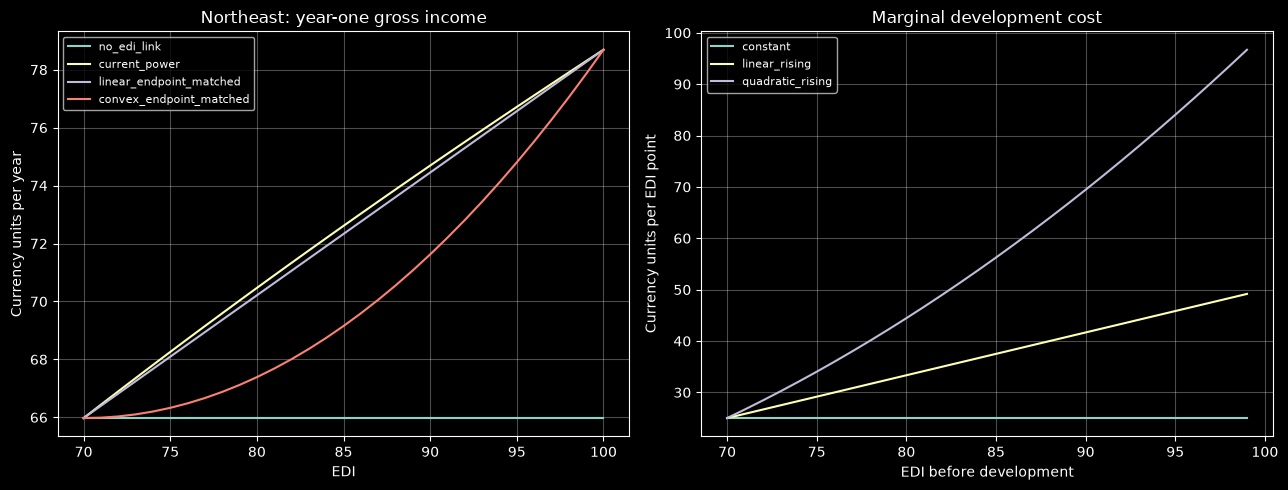

In [29]:
example_region = REGIONAL_ECONOMIC_PARAMETERS[0]
example_initial_edi = int(example_region["initial_edi"])
example_edi_values = list(range(example_initial_edi, 101))
figure, axes = plt.subplots(1, 2, figsize=(13, 5))

for curve_name in INCOME_CURVES:
    income_values = []
    for edi_value in example_edi_values:
        income_values.append(calculate_income_curve(example_region, 1, edi_value, curve_name))
    axes[0].plot(example_edi_values, income_values, label=curve_name)

for cost_shape in COST_SHAPES:
    cost_values = []
    for edi_value in example_edi_values[:-1]:
        cost_values.append(calculate_marginal_development_cost(edi_value, example_initial_edi, cost_shape))
    axes[1].plot(example_edi_values[:-1], cost_values, label=cost_shape)

axes[0].set_title("Northeast: year-one gross income")
axes[0].set_xlabel("EDI")
axes[0].set_ylabel("Currency units per year")
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8)
axes[1].set_title("Marginal development cost")
axes[1].set_xlabel("EDI before development")
axes[1].set_ylabel("Currency units per EDI point")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8)
figure.tight_layout()
plt.show()

The plot makes the structural difference visible: with the current fixed development price, the income curve rises while the cost line stays horizontal. Rising marginal-cost alternatives make the last development points more expensive. The displayed curves use the Northeast as an example; the tables include all four regional baselines.

At EDI 100, the current income equation raises gross income by about 15-34% over each region's initial EDI level. That means the current income-to-development-cost ratio also rises by 15-34% because the development price stays at 25. By comparison, the quadratic marginal-cost curve raises the last-point price to about 96-98 units. Note that year-one gross income covers only 0.70-0.91 of that point. Total development cost to EDI 100 becomes about 2.27-2.30 times the constant-cost total.

In [30]:
cost_sensitivity_rows = []
for multiplier in (0.5, 1.0, 2.0):
    development_cost_result = evaluate_fixed_policies(EnvironmentConfig(get_parameters(episode_steps=EPISODE_YEARS)),
                                                      policy_names=("balanced",), currency_multipliers=(1.0,), seeds=(0,),
                                                      development_cost_multiplier=multiplier)[0]
    cost_sensitivity_rows.append({
        "cost_test": "development cost",
        "cost_multiplier": multiplier,
        "starting_currency_multiplier": 1.0,
        "final_mean_EDI": development_cost_result["final_mean_EDI"],
        "development_spending": development_cost_result["development_spending"],
        "mitigation_spending": development_cost_result["mitigation_spending"],
        "unaffordable_development_attempts": development_cost_result["unaffordable_development_attempts"],
        "unaffordable_investment_attempts": development_cost_result["unaffordable_investment_attempts"],
    })

    investment_cost_result = evaluate_fixed_policies(EnvironmentConfig(get_parameters(episode_steps=EPISODE_YEARS)),
                                                     policy_names=("balanced",), currency_multipliers=(1.0,), seeds=(0,),
                                                     investment_cost_multiplier=multiplier)[0]
    cost_sensitivity_rows.append({
        "cost_test": "investment cost",
        "cost_multiplier": multiplier,
        "starting_currency_multiplier": 1.0,
        "final_mean_EDI": investment_cost_result["final_mean_EDI"],
        "development_spending": investment_cost_result["development_spending"],
        "mitigation_spending": investment_cost_result["mitigation_spending"],
        "unaffordable_development_attempts": investment_cost_result["unaffordable_development_attempts"],
        "unaffordable_investment_attempts": investment_cost_result["unaffordable_investment_attempts"],
    })

cost_sensitivity = pd.DataFrame(cost_sensitivity_rows)
display(cost_sensitivity.round(2))

,cost_test,cost_multiplier,starting_currency_multiplier,final_mean_EDI,development_spending,mitigation_spending,unaffordable_development_attempts,unaffordable_investment_attempts
0,development cost,0.5,1.0,98.75,1687.5,6400.0,0,0
1,investment cost,0.5,1.0,98.75,3375.0,3200.0,0,0
2,development cost,1.0,1.0,98.75,3375.0,6400.0,0,0
3,investment cost,1.0,1.0,98.75,3375.0,6400.0,0,0
4,development cost,2.0,1.0,98.75,6750.0,6400.0,0,0
5,investment cost,2.0,1.0,98.75,3375.0,12800.0,0,6


In the refreshed 40-year sensitivity runs, halving or doubling the development-cost multiplier does not change balanced-policy mean final EDI (98.75), and no development attempt is unaffordable. Doubling development costs raises development spending from 3,375 to 6,750 currency units and lowers remaining currency, but it does not constrain development within this horizon. Doubling investment costs also leaves final EDI at 98.75. It produces six unaffordable investment attempts, which are retried under the existing policy rule. These results show that the current income and starting-resource assumptions can absorb substantial cost increases in this test. The multipliers are sensitivity tests, not recommended prices.

## Environmental benefit per currency unit

To isolate project effects from development, each region holds EDI at its initial value. A single project package is purchased in year one, then regions maintain for the rest of the 40-year episode. The matched baseline also maintains throughout. Benefits are reported separately in each pollutant's own units as the cumulative difference in annual exposure or stock over the run; those different units should not be combined into a single ranking.

In [31]:
investment_cases = [("no_investment", "maintain"), ("prevention_focused", "prevention"),
                    ("cleanup_focused", "cleanup"), ("balanced", "balanced")]

investment_trajectories = {}
investment_spending = {}
for case_name, first_year_action in investment_cases:
    investment_environment = Study3IntegratedEnvironment(EnvironmentConfig(get_parameters(episode_steps=EPISODE_YEARS)),
                                                         starting_currency_multiplier=1.0)
    investment_environment.reset(seed=0)
    case_trajectory = []
    for year_index in range(EPISODE_YEARS):
        action_name = "maintain"
        if year_index == 0:
            action_name = first_year_action
        observations, terminated, truncated, info = investment_environment.step((action_name,) * len(investment_environment.regions))
        case_trajectory.append(info)
    investment_trajectories[case_name] = case_trajectory
    investment_spending[case_name] = sum(investment_environment.investment_spending)

In [32]:
metric_names = ["PM2.5", "CO2", "Nitrate-N", "Lead total", "Lead mobile"]
metric_units = {"PM2.5": "ug/m^3-years", "CO2": "ppm-years", "Nitrate-N": "mg N/L-years",
                "Lead total": "kg-years per parcel", "Lead mobile": "kg-years per parcel"}

metric_trajectories = {}
for case_name, case_trajectory in investment_trajectories.items():
    case_metrics = {}
    for metric_name in metric_names:
        case_metrics[metric_name] = []
    for info in case_trajectory:
        pm25_mean = sum(info["stocks"]["PM2.5"]) / len(info["stocks"]["PM2.5"])
        nitrate_concentrations = []
        for nitrate_stock in info["stocks"]["Nitrate-N"]:
            nitrate_concentrations.append(1000 * nitrate_stock / reference_config.nitrate["water_volume_m3"])

        nitrate_mean = sum(nitrate_concentrations) / len(nitrate_concentrations)
        lead_total_mean = sum(info["stocks"]["Lead"]) / len(info["stocks"]["Lead"])
        lead_mobile_mean = sum(info["mobile_stocks"]["Lead"]) / len(info["mobile_stocks"]["Lead"])
        case_metrics["PM2.5"].append(pm25_mean)
        case_metrics["CO2"].append(info["stocks"]["CO2"])
        case_metrics["Nitrate-N"].append(nitrate_mean)
        case_metrics["Lead total"].append(lead_total_mean)
        case_metrics["Lead mobile"].append(lead_mobile_mean)
    metric_trajectories[case_name] = case_metrics

In [33]:
benefit_rows = []
for case_name in investment_trajectories:
    if case_name == "no_investment":
        continue
    for metric_name in metric_names:
        cumulative_reduction = 0.0
        for year_index in range(EPISODE_YEARS):
            baseline_value = metric_trajectories["no_investment"][metric_name][year_index]
            investment_value = metric_trajectories[case_name][metric_name][year_index]
            cumulative_reduction += baseline_value - investment_value
        total_cost = investment_spending[case_name]
        benefit_rows.append({
            "investment_package": case_name,
            "pollutant_measure": metric_name,
            "cumulative_reduction": cumulative_reduction,
            "unit": metric_units[metric_name],
            "total_currency_spent": total_cost,
            "reduction_per_currency_unit": cumulative_reduction / total_cost,
        })

investment_benefits = pd.DataFrame(benefit_rows)
display(investment_benefits.round(5))

,investment_package,pollutant_measure,cumulative_reduction,unit,total_currency_spent,reduction_per_currency_unit
0,prevention_focused,PM2.5,0.15375,ug/m^3-years,320.0,0.00048
1,prevention_focused,CO2,11.04828,ppm-years,320.0,0.03453
2,prevention_focused,Nitrate-N,2.25750,mg N/L-years,320.0,0.00705
3,prevention_focused,Lead total,4.62466,kg-years per parcel,320.0,0.01445
4,prevention_focused,Lead mobile,0.00179,kg-years per parcel,320.0,0.00001
5,cleanup_focused,PM2.5,0.00000,ug/m^3-years,400.0,0.00000
6,cleanup_focused,CO2,0.66235,ppm-years,400.0,0.00166
7,cleanup_focused,Nitrate-N,0.61251,mg N/L-years,400.0,0.00153
8,cleanup_focused,Lead total,19.85222,kg-years per parcel,400.0,0.04963
9,cleanup_focused,Lead mobile,0.00767,kg-years per parcel,400.0,0.00002


For a given pollutant measure, larger reduction per currency unit indicates more cumulative benefit under this one-purchase experiment. Cleanup removes accumulated nitrate and lead and removes CO2 from the shared atmospheric stock. Balanced buys both types of project and lead containment. These are short-run responses under the assumed delay, project lifetime, and cleanup capacity.

In this run, prevention gives the largest cumulative benefit per currency unit for PM2.5, CO2, and nitrate-N. Cleanup is most efficient for reducing total soil lead. balanced has the largest mobile-lead benefit per currency unit because it also includes containment. The balanced package produces the largest absolute reduction for CO2, nitrate, and total lead, but its broader package costs more. These rankings are specific to this single-purchase, 40-year comparison and the assumed project parameters.